<a href="https://colab.research.google.com/github/kumarsaurabh1817/Final-Computer-Vision-Training/blob/main/week3_detection/day3_segmentation/Week3_Day3_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 3 · Day 3 — Semantic vs Instance Segmentation

**Goal:** understand what a segmentation model outputs (per-pixel class scores vs per-object masks), run pretrained models of both kinds, and train a **U-Net from scratch**.

| Part | Model | Output you will inspect |
|---|---|---|
| A · Pretrained semantic | DeepLabV3-ResNet50 (21 VOC classes) | `(1, 21, H, W)` logits → `argmax` → one class per pixel |
| B · Pretrained instance | Mask R-CNN (torchvision; same architecture as Detectron2's) + YOLO26-seg | One soft mask **per object** + box + label + score |
| C · Train | U-Net (from scratch) on Oxford-IIIT Pet trimaps | 3-class mask: pet / background / border |
| D · Compare | U-Net vs zero-shot DeepLabV3 on pet-vs-background IoU | Metric table + error maps |

**Datasets (both auto-download):**
- [Oxford-IIIT Pet (Kaggle: julinmaloof/the-oxfordiiit-pet-dataset)](https://www.kaggle.com/datasets/julinmaloof/the-oxfordiiit-pet-dataset) — 7,390 images with pixel trimaps (~780 MB). Falls back to the torchvision downloader if Kaggle is unavailable.
- [COCO128 (Kaggle: ultralytics/coco128)](https://www.kaggle.com/datasets/ultralytics/coco128) — multi-object street/indoor scenes for the instance demo (~7 MB).

> Runtime: **T4 GPU**. `FULL_RUN=True` (25 U-Net epochs at 256 px) takes ~20–30 min on a T4.

## 0 · Install dependencies

In [1]:
import subprocess
import sys


def pip_install(*packages: str) -> None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])


pip_install("ultralytics==8.4.182", "kagglehub==1.0.2")

## 1 · Configuration

In [2]:
import json
import random
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision.models.detection import MaskRCNN_ResNet50_FPN_V2_Weights, maskrcnn_resnet50_fpn_v2
from torchvision.models.segmentation import DeepLabV3_ResNet50_Weights, deeplabv3_resnet50
from torchvision.transforms.functional import to_tensor

FULL_RUN = True
SEED = 42
IMG_SIZE = 256
EPOCHS = 25 if FULL_RUN else 2
BATCH_SIZE = 16
LR = 1e-3
BASE_CHANNELS = 32
VAL_FRACTION = 0.1
MAX_IMAGES = None if FULL_RUN else 800
N_COMPARE = 500  # test images used for the U-Net vs DeepLabV3 comparison
SEG_CLASSES = ["pet", "background", "border"]  # trimap values 1, 2, 3 -> 0, 1, 2

IN_COLAB = "google.colab" in sys.modules
try:
    HERE = Path(__file__).resolve().parent
except NameError:
    HERE = Path.cwd()
OUTPUT_DIR = Path("/content/week3_outputs/day3") if IN_COLAB else HERE.parent / "results" / "day3"
DATA_DIR = Path("/content/datasets") if IN_COLAB else HERE.parent / "data"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything()
print({"device": str(DEVICE), "full_run": FULL_RUN, "epochs": EPOCHS, "img_size": IMG_SIZE})


def save_fig(fig, name: str) -> None:
    path = OUTPUT_DIR / name
    fig.savefig(path, dpi=120, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)
    print(f"saved -> {path}")

{'device': 'cuda', 'full_run': True, 'epochs': 25, 'img_size': 256}


## 2 · Download the datasets

In [3]:
import kagglehub


def get_pets() -> tuple[Path, Path, Path | None]:
    """Return (images_dir, trimaps_dir, annotations_dir)."""
    try:
        root = Path(kagglehub.dataset_download("julinmaloof/the-oxfordiiit-pet-dataset"))
    except Exception as exc:
        print(f"Kaggle download failed ({exc}); using torchvision's OxfordIIITPet downloader")
        from torchvision.datasets import OxfordIIITPet

        OxfordIIITPet(str(DATA_DIR), split="trainval", target_types="segmentation", download=True)
        root = DATA_DIR / "oxford-iiit-pet"
    trimap_dirs = [d for d in root.rglob("trimaps") if d.is_dir() and any(d.glob("[!.]*.png"))]
    image_dirs = sorted(
        {p.parent for p in root.rglob("*.jpg") if not p.name.startswith("._")},
        key=lambda d: -sum(1 for _ in d.glob("*.jpg")),
    )
    if not trimap_dirs or not image_dirs:
        raise FileNotFoundError(f"Could not find images/ and trimaps/ below {root}")
    return image_dirs[0], trimap_dirs[0], trimap_dirs[0].parent


PET_IMAGES, PET_TRIMAPS, PET_ANNOTATIONS = get_pets()
print("images :", PET_IMAGES, len(list(PET_IMAGES.glob("*.jpg"))))
print("trimaps:", PET_TRIMAPS, len(list(PET_TRIMAPS.glob("[!.]*.png"))))

coco_root = Path(kagglehub.dataset_download("ultralytics/coco128"))
COCO_IMAGES = next(d for d in coco_root.rglob("train2017") if d.parent.name == "images")
COCO_LABELS = COCO_IMAGES.parent.parent / "labels" / "train2017"
print("coco128:", COCO_IMAGES)

100%|██████████| 777M/777M [00:07<00:00, 105MB/s]

Extracting files...


images : /root/.cache/kagglehub/datasets/julinmaloof/the-oxfordiiit-pet-dataset/versions/1/images 7390
trimaps: /root/.cache/kagglehub/datasets/julinmaloof/the-oxfordiiit-pet-dataset/versions/1/annotations/trimaps 7390


100%|██████████| 6.66M/6.66M [00:00<00:00, 80.9MB/s]

Extracting files...
coco128: /root/.cache/kagglehub/datasets/ultralytics/coco128/versions/3/coco128/images/train2017


## 3 · What does a segmentation label look like?

A trimap is a single-channel PNG the same size as the image where each pixel stores a class id: **1 = pet, 2 = background, 3 = border/uncertain**. We shift it to 0-based ids. Masks must be resized with **nearest-neighbour** interpolation; bilinear would invent ids like 1.5 at object edges.

image size: (600, 400) | mask shape: (400, 600) | dtype: uint8 | unique ids: [1 2 3]


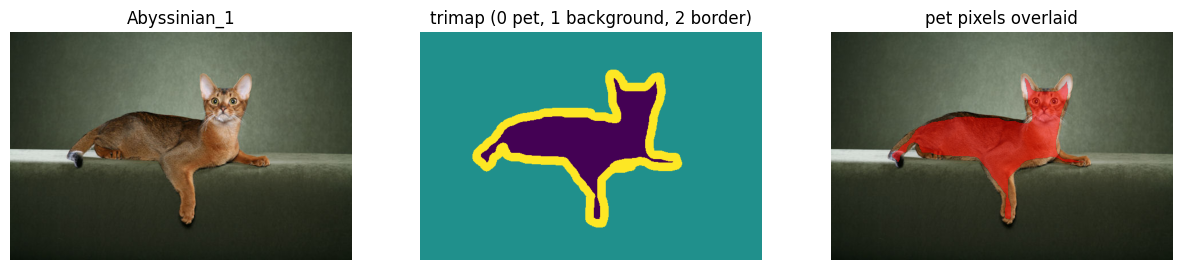

saved -> /content/week3_outputs/day3/day3_trimap_example.png


In [4]:
example = sorted(PET_TRIMAPS.glob("[!.]*.png"))[0]
img = Image.open(PET_IMAGES / f"{example.stem}.jpg").convert("RGB")
trimap = np.array(Image.open(example))
print("image size:", img.size, "| mask shape:", trimap.shape, "| dtype:", trimap.dtype, "| unique ids:", np.unique(trimap))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img)
axes[0].set_title(example.stem)
axes[1].imshow(trimap - 1, cmap="viridis", vmin=0, vmax=2)
axes[1].set_title("trimap (0 pet, 1 background, 2 border)")
axes[2].imshow(img)
axes[2].imshow(np.ma.masked_where(trimap != 1, trimap), alpha=0.5, cmap="autumn")
axes[2].set_title("pet pixels overlaid")
for ax in axes:
    ax.axis("off")
save_fig(fig, "day3_trimap_example.png")

## Part A · Pretrained semantic segmentation (DeepLabV3)

Semantic segmentation assigns **one class to every pixel** and has no notion of "which object". DeepLabV3 returns a dict whose `"out"` tensor has shape `(batch, num_classes, H, W)`: raw logits per class per pixel. `softmax` over dim 1 gives per-pixel probabilities, and `argmax` gives the label map.

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:01<00:00, 167MB/s]


VOC classes: ['__background__', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse', 'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']
logits: (21, 400, 600) -> label map: (400, 600)
  __background__  43.6% of pixels, mean confidence 0.86
  cat            9.1% of pixels, mean confidence 0.83
  dog            3.8% of pixels, mean confidence 0.70
  sofa          43.5% of pixels, mean confidence 0.85


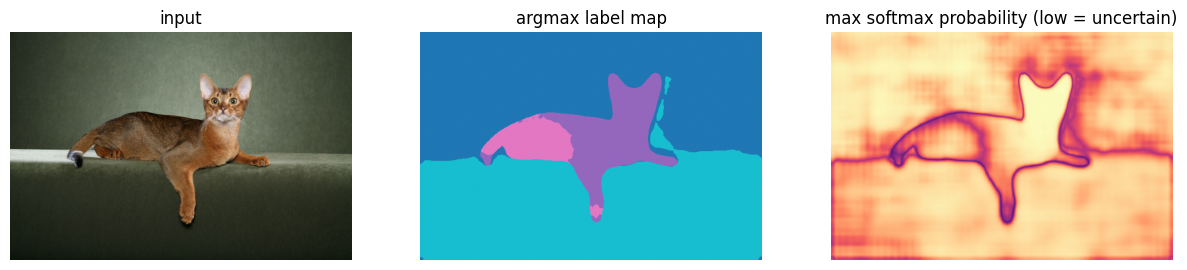

saved -> /content/week3_outputs/day3/day3_deeplab_output.png


In [5]:
deeplab_weights = DeepLabV3_ResNet50_Weights.DEFAULT
deeplab = deeplabv3_resnet50(weights=deeplab_weights).to(DEVICE).eval()
deeplab_preprocess = deeplab_weights.transforms()
VOC_CLASSES = deeplab_weights.meta["categories"]
PET_VOC_IDS = [VOC_CLASSES.index("cat"), VOC_CLASSES.index("dog")]
print("VOC classes:", VOC_CLASSES)


@torch.no_grad()
def deeplab_logits(image: Image.Image, out_size: tuple[int, int] | None = None) -> torch.Tensor:
    x = deeplab_preprocess(image).unsqueeze(0).to(DEVICE)
    logits = deeplab(x)["out"]
    size = out_size or (image.height, image.width)
    return F.interpolate(logits, size=size, mode="bilinear", align_corners=False)[0]


logits = deeplab_logits(img)
probs = logits.softmax(0)
label_map = probs.argmax(0).cpu().numpy()
print("logits:", tuple(logits.shape), "-> label map:", label_map.shape)
for cid in np.unique(label_map):
    print(f"  {VOC_CLASSES[cid]:<12} {100 * (label_map == cid).mean():5.1f}% of pixels, "
          f"mean confidence {probs[cid][torch.from_numpy(label_map == cid).to(DEVICE)].mean():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img)
axes[0].set_title("input")
axes[1].imshow(label_map, cmap="tab20", vmin=0, vmax=20)
axes[1].set_title("argmax label map")
axes[2].imshow(probs.max(0).values.cpu(), cmap="magma", vmin=0, vmax=1)
axes[2].set_title("max softmax probability (low = uncertain)")
for ax in axes:
    ax.axis("off")
save_fig(fig, "day3_deeplab_output.png")

## Part B · Pretrained instance segmentation (Mask R-CNN and YOLO26-seg)

Instance segmentation separates **individual objects**: two people get two masks. Mask R-CNN is Faster R-CNN (Day 1) plus a small FCN head that predicts a 28×28 mask inside each detected box, pasted back at full resolution. torchvision's implementation mirrors Detectron2's reference model and installs without compilation on Colab.

Output per image: `boxes (N,4)`, `labels (N)`, `scores (N)`, and `masks (N,1,H,W)` with **soft** probabilities. Threshold at 0.5 to get binary masks.

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:01<00:00, 171MB/s]


{'boxes': (100, 4), 'labels': (100,), 'scores': (100,), 'masks': (100, 1, 480, 640)}
mask value range: 0.0 → 0.9998171329498291 (soft probabilities)


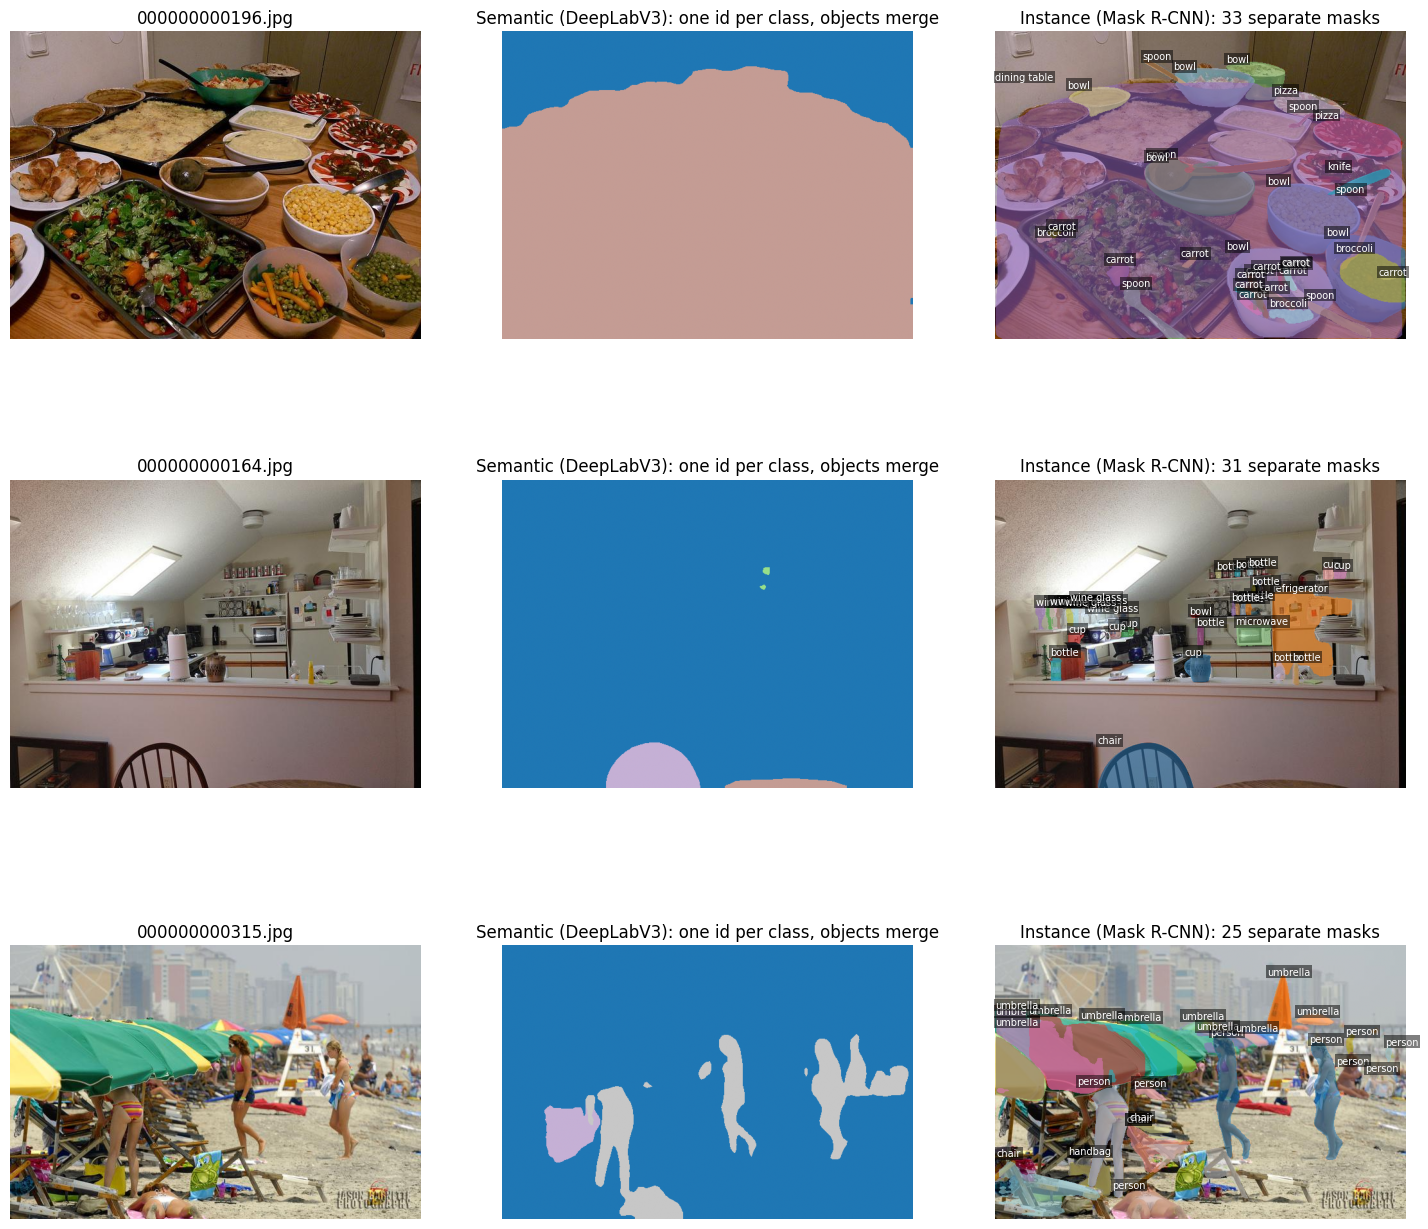

saved -> /content/week3_outputs/day3/day3_semantic_vs_instance.png


In [6]:
maskrcnn_weights = MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT
maskrcnn = maskrcnn_resnet50_fpn_v2(weights=maskrcnn_weights).to(DEVICE).eval()
COCO_CATEGORIES = maskrcnn_weights.meta["categories"]


def n_objects(label_path: Path) -> int:
    return len(label_path.read_text().strip().splitlines()) if label_path.exists() else 0


busy_images = sorted(COCO_IMAGES.glob("*.jpg"), key=lambda p: -n_objects(COCO_LABELS / f"{p.stem}.txt"))[:3]

with torch.no_grad():
    demo_img = Image.open(busy_images[0]).convert("RGB")
    out = maskrcnn([to_tensor(demo_img).to(DEVICE)])[0]
print({k: tuple(v.shape) for k, v in out.items()})
print("mask value range:", float(out["masks"].min()), "→", float(out["masks"].max()), "(soft probabilities)")


def instance_overlay(image: Image.Image, output: dict, score_thr: float = 0.6) -> np.ndarray:
    canvas = np.asarray(image).astype(float) / 255
    keep = output["scores"] >= score_thr
    masks = (output["masks"][keep, 0] >= 0.5).cpu().numpy()
    colors = plt.cm.tab20(np.linspace(0, 1, max(len(masks), 1)))[:, :3]
    for mask, color in zip(masks, colors):
        canvas[mask] = 0.45 * canvas[mask] + 0.55 * color
    return canvas


fig, axes = plt.subplots(len(busy_images), 3, figsize=(18, 5.5 * len(busy_images)))
for row, path in enumerate(busy_images):
    image = Image.open(path).convert("RGB")
    with torch.no_grad():
        out = maskrcnn([to_tensor(image).to(DEVICE)])[0]
    semantic = deeplab_logits(image).argmax(0).cpu().numpy()
    keep = out["scores"] >= 0.6
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(path.name)
    axes[row, 1].imshow(semantic, cmap="tab20", vmin=0, vmax=20)
    axes[row, 1].set_title("Semantic (DeepLabV3): one id per class, objects merge")
    axes[row, 2].imshow(instance_overlay(image, out))
    for box, label in zip(out["boxes"][keep].cpu().numpy(), out["labels"][keep].cpu().numpy()):
        axes[row, 2].text(box[0], box[1], COCO_CATEGORIES[label], fontsize=7, color="white", bbox=dict(facecolor="black", alpha=0.5, pad=1, lw=0))
    axes[row, 2].set_title(f"Instance (Mask R-CNN): {int(keep.sum())} separate masks")
    for ax in axes[row]:
        ax.axis("off")
save_fig(fig, "day3_semantic_vs_instance.png")

### YOLO26-seg: the one-stage alternative

YOLO-seg predicts a small set of **prototype masks** for the whole image plus mask coefficients per detection; each instance mask is a linear combination of prototypes. `results.masks.data` holds the binary masks and `results.masks.xy` the polygon outlines (the format YOLO segmentation labels use).

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
masks.data: (14, 640, 640) | first polygon points: (190, 2)
Latency on one image: YOLO26n-seg 89 ms | Mask R-CNN 349 ms


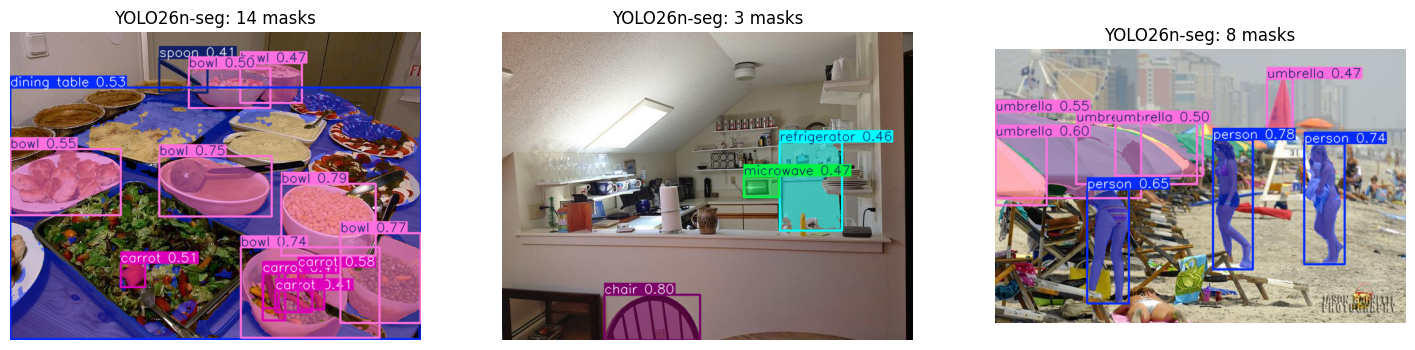

saved -> /content/week3_outputs/day3/day3_yolo_seg.png


In [7]:
from ultralytics import YOLO

yolo_seg = YOLO("yolo26n-seg.pt")
seg_results = yolo_seg.predict([str(p) for p in busy_images], conf=0.4, verbose=False, device=0 if DEVICE.type == "cuda" else "cpu")
r0 = seg_results[0]
if r0.masks is not None:
    print("masks.data:", tuple(r0.masks.data.shape), "| first polygon points:", r0.masks.xy[0].shape)

t0 = time.perf_counter()
_ = yolo_seg.predict(str(busy_images[0]), verbose=False, device=0 if DEVICE.type == "cuda" else "cpu")
yolo_seg_ms = (time.perf_counter() - t0) * 1000
with torch.no_grad():
    x = to_tensor(Image.open(busy_images[0]).convert("RGB")).to(DEVICE)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    maskrcnn([x])
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    maskrcnn_ms = (time.perf_counter() - t0) * 1000
print(f"Latency on one image: YOLO26n-seg {yolo_seg_ms:.0f} ms | Mask R-CNN {maskrcnn_ms:.0f} ms")

fig, axes = plt.subplots(1, len(seg_results), figsize=(6 * len(seg_results), 5))
for ax, res in zip(np.atleast_1d(axes), seg_results):
    ax.imshow(res.plot()[..., ::-1])
    ax.set_title(f"YOLO26n-seg: {0 if res.masks is None else len(res.masks)} masks")
    ax.axis("off")
save_fig(fig, "day3_yolo_seg.png")

## Part C · Train a U-Net from scratch on Oxford-IIIT Pet

**U-Net** = an encoder that halves resolution while doubling channels (what is in the image), a decoder that upsamples back (where it is), and **skip connections** that concatenate encoder features into the decoder at each scale so fine boundaries survive the bottleneck.

### C.1 Load, validate, and cache the data
Images and masks are resized once to 256×256 and kept in RAM (~1.5 GB) so the GPU is not starved by JPEG decoding.

In [8]:
def read_split_list(name: str) -> list[str]:
    path = PET_ANNOTATIONS / name if PET_ANNOTATIONS else None
    if path is None or not path.exists():
        return []
    return [line.split()[0] for line in path.read_text().splitlines() if line.strip() and not line.startswith("#")]


available = {p.stem for p in PET_TRIMAPS.glob("[!.]*.png")} & {p.stem for p in PET_IMAGES.glob("[!.]*.jpg")}
trainval_ids = [s for s in read_split_list("trainval.txt") if s in available]
test_ids = [s for s in read_split_list("test.txt") if s in available]
if not trainval_ids or not test_ids:  # no official lists -> deterministic 50/50 split
    ids = sorted(available)
    random.Random(SEED).shuffle(ids)
    trainval_ids, test_ids = ids[: len(ids) // 2], ids[len(ids) // 2 :]
if MAX_IMAGES:
    trainval_ids, test_ids = trainval_ids[:MAX_IMAGES], test_ids[: MAX_IMAGES // 2]


def load_pair(stem: str):
    try:
        image = Image.open(PET_IMAGES / f"{stem}.jpg").convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        mask = Image.open(PET_TRIMAPS / f"{stem}.png").resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)
        mask = np.array(mask).astype(np.int64) - 1
        if mask.min() < 0 or mask.max() > 2:
            return None
        return np.asarray(image, dtype=np.uint8), mask.astype(np.uint8)
    except Exception:  # a handful of files in this dataset are corrupt
        return None


def cache(stems: list[str]):
    with ThreadPoolExecutor(max_workers=8) as pool:
        pairs = list(pool.map(load_pair, stems))
    kept = [(s, p) for s, p in zip(stems, pairs) if p is not None]
    print(f"  cached {len(kept)}/{len(stems)} (skipped {len(stems) - len(kept)} unreadable)")
    return [s for s, _ in kept], np.stack([p[0] for _, p in kept]), np.stack([p[1] for _, p in kept])


t0 = time.time()
trainval_ids, trainval_x, trainval_y = cache(trainval_ids)
test_ids, test_x, test_y = cache(test_ids)
print(f"Caching took {time.time() - t0:.0f}s")

perm = np.random.default_rng(SEED).permutation(len(trainval_ids))
n_val = int(len(perm) * VAL_FRACTION)
val_idx, train_idx = perm[:n_val], perm[n_val:]
print(f"train={len(train_idx)} val={len(val_idx)} test={len(test_ids)}")
print("Pixel class balance (train):", {c: f"{100 * (trainval_y[train_idx] == i).mean():.1f}%" for i, c in enumerate(SEG_CLASSES)})

  cached 3680/3680 (skipped 0 unreadable)
  cached 3669/3669 (skipped 0 unreadable)
Caching took 35s
train=3312 val=368 test=3669
Pixel class balance (train): {'pet': '30.0%', 'background': '58.6%', 'border': '11.4%'}


### C.2 Dataset with joint augmentation

Geometric augmentations must be applied **identically** to the image and the mask; photometric ones (brightness/contrast) only to the image.

In [9]:
class PetSegDataset(Dataset):
    def __init__(self, images: np.ndarray, masks: np.ndarray, augment: bool):
        self.images, self.masks, self.augment = images, masks, augment

    def __len__(self) -> int:
        return len(self.images)

    def __getitem__(self, i: int):
        image = torch.from_numpy(self.images[i]).permute(2, 0, 1).float() / 255
        mask = torch.from_numpy(self.masks[i]).long()
        if self.augment:
            if torch.rand(1) < 0.5:  # geometric: image AND mask
                image, mask = image.flip(-1), mask.flip(-1)
            contrast = float(torch.empty(1).uniform_(0.8, 1.2))  # photometric: image only
            brightness = float(torch.empty(1).uniform_(-0.1, 0.1))
            image = (image * contrast + brightness).clamp(0, 1)
        return (image - IMAGENET_MEAN) / IMAGENET_STD, mask


g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(PetSegDataset(trainval_x[train_idx], trainval_y[train_idx], True), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=2, pin_memory=True, drop_last=True, generator=g)
val_loader = DataLoader(PetSegDataset(trainval_x[val_idx], trainval_y[val_idx], False), batch_size=BATCH_SIZE * 2, num_workers=2)
test_loader = DataLoader(PetSegDataset(test_x, test_y, False), batch_size=BATCH_SIZE * 2, num_workers=2)

### C.3 The U-Net

In [10]:
class DoubleConv(nn.Sequential):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )


class UNet(nn.Module):
    def __init__(self, in_channels: int = 3, num_classes: int = 3, base: int = 32, depth: int = 4):
        super().__init__()
        chs = [base * 2**i for i in range(depth + 1)]  # e.g. 32, 64, 128, 256, 512
        self.encoders = nn.ModuleList([DoubleConv(in_channels, chs[0])] + [DoubleConv(chs[i], chs[i + 1]) for i in range(depth - 1)])
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(chs[depth - 1], chs[depth])
        self.upsamples = nn.ModuleList([nn.ConvTranspose2d(chs[i + 1], chs[i], 2, stride=2) for i in reversed(range(depth))])
        self.decoders = nn.ModuleList([DoubleConv(chs[i] * 2, chs[i]) for i in reversed(range(depth))])
        self.head = nn.Conv2d(chs[0], num_classes, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        skips = []
        for enc in self.encoders:
            x = enc(x)
            skips.append(x)  # saved for the skip connection
            x = self.pool(x)
        x = self.bottleneck(x)
        for up, dec, skip in zip(self.upsamples, self.decoders, reversed(skips)):
            x = up(x)
            x = dec(torch.cat([x, skip], dim=1))  # skip connection: concat encoder features
        return self.head(x)  # (B, num_classes, H, W) logits


unet = UNet(num_classes=len(SEG_CLASSES), base=BASE_CHANNELS).to(DEVICE)
with torch.no_grad():
    print("U-Net output for a (2,3,256,256) batch:", tuple(unet(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)).shape))
print(f"Parameters: {sum(p.numel() for p in unet.parameters()) / 1e6:.2f} M")

U-Net output for a (2,3,256,256) batch: (2, 3, 256, 256)
Parameters: 7.76 M


### C.4 Loss and metrics

- **Cross-entropy** scores every pixel independently; **Dice loss** scores region overlap per class and helps the rare `border` class. We use their sum.
- **IoU (Jaccard)** per class = TP / (TP + FP + FN); **mIoU** averages it over classes. **Dice** = 2TP / (2TP + FP + FN). Pixel accuracy alone is misleading when background dominates.

In [11]:
def dice_loss(logits: torch.Tensor, target: torch.Tensor, eps: float = 1.0) -> torch.Tensor:
    probs = logits.float().softmax(1)
    onehot = F.one_hot(target, probs.shape[1]).permute(0, 3, 1, 2).float()
    inter = (probs * onehot).sum((0, 2, 3))
    denom = probs.sum((0, 2, 3)) + onehot.sum((0, 2, 3))
    return 1 - ((2 * inter + eps) / (denom + eps)).mean()


def confusion(pred: torch.Tensor, target: torch.Tensor, n: int) -> torch.Tensor:
    return torch.bincount(target.flatten() * n + pred.flatten(), minlength=n * n).reshape(n, n)  # rows=GT


def seg_metrics(cm: torch.Tensor) -> dict:
    cm = cm.double()
    tp = cm.diag()
    iou = tp / (cm.sum(0) + cm.sum(1) - tp).clamp(min=1)
    dice = 2 * tp / (cm.sum(0) + cm.sum(1)).clamp(min=1)
    return {"pixel_acc": float(tp.sum() / cm.sum()), "mIoU": float(iou.mean()),
            "IoU": {c: float(v) for c, v in zip(SEG_CLASSES, iou)}, "Dice": {c: float(v) for c, v in zip(SEG_CLASSES, dice)}}


@torch.no_grad()
def evaluate_unet(model: nn.Module, loader: DataLoader) -> dict:
    model.eval()
    cm = torch.zeros(len(SEG_CLASSES), len(SEG_CLASSES), dtype=torch.long, device=DEVICE)
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            pred = model(x).argmax(1)
        cm += confusion(pred, y, len(SEG_CLASSES))
    return seg_metrics(cm)

### C.5 Training loop (AMP + cosine LR, best checkpoint by val mIoU)

epoch  1/25 loss=1.4775 val mIoU=0.5019 pixel acc=0.7386 (36s)
epoch  2/25 loss=0.9458 val mIoU=0.6034 pixel acc=0.8327 (35s)
epoch  3/25 loss=0.7737 val mIoU=0.6252 pixel acc=0.8400 (36s)
epoch  4/25 loss=0.6987 val mIoU=0.6578 pixel acc=0.8533 (36s)
epoch  5/25 loss=0.6461 val mIoU=0.6765 pixel acc=0.8663 (37s)
epoch  6/25 loss=0.6013 val mIoU=0.6891 pixel acc=0.8730 (37s)
epoch  7/25 loss=0.5890 val mIoU=0.7015 pixel acc=0.8795 (37s)
epoch  8/25 loss=0.5571 val mIoU=0.6992 pixel acc=0.8823 (38s)
epoch  9/25 loss=0.5358 val mIoU=0.7000 pixel acc=0.8817 (38s)
epoch 10/25 loss=0.5185 val mIoU=0.7040 pixel acc=0.8835 (38s)
epoch 11/25 loss=0.4937 val mIoU=0.7261 pixel acc=0.8904 (38s)
epoch 12/25 loss=0.4802 val mIoU=0.7355 pixel acc=0.9012 (38s)
epoch 13/25 loss=0.4517 val mIoU=0.7288 pixel acc=0.8962 (39s)
epoch 14/25 loss=0.4353 val mIoU=0.7421 pixel acc=0.9027 (39s)
epoch 15/25 loss=0.4183 val mIoU=0.7440 pixel acc=0.9048 (39s)
epoch 16/25 loss=0.4012 val mIoU=0.7430 pixel acc=0.902

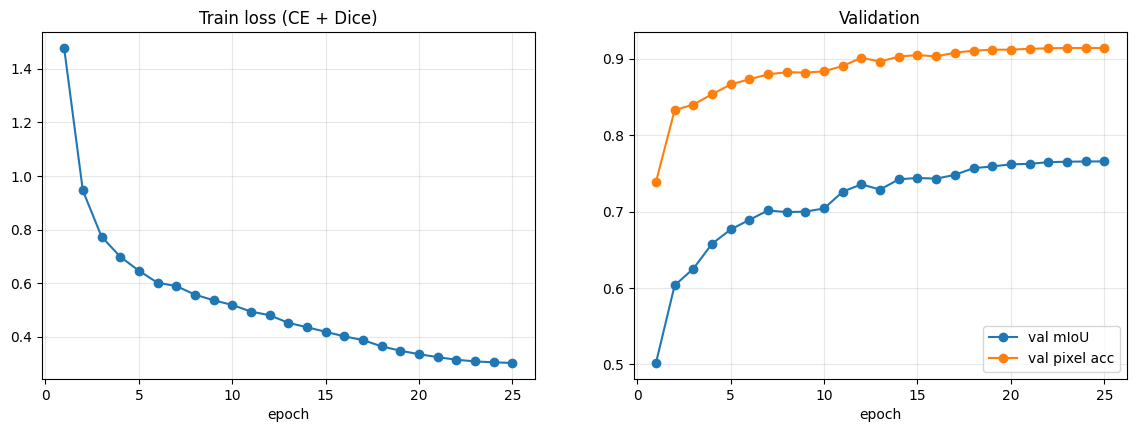

saved -> /content/week3_outputs/day3/day3_unet_curves.png


In [12]:
optimizer = torch.optim.AdamW(unet.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, total_steps=EPOCHS * len(train_loader), pct_start=0.1)
scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_AMP)
ce_loss = nn.CrossEntropyLoss()
BEST_PATH = OUTPUT_DIR / "unet_pets_best.pt"
history = {"train_loss": [], "val_mIoU": [], "val_pixel_acc": []}
best_miou = -1.0

for epoch in range(1, EPOCHS + 1):
    unet.train()
    t0, running = time.time(), 0.0
    for x, y in train_loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            logits = unet(x)
            loss = ce_loss(logits, y) + dice_loss(logits, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        running += loss.item() * x.size(0)
    train_loss = running / (len(train_loader) * BATCH_SIZE)
    val = evaluate_unet(unet, val_loader)
    history["train_loss"].append(train_loss)
    history["val_mIoU"].append(val["mIoU"])
    history["val_pixel_acc"].append(val["pixel_acc"])
    if val["mIoU"] > best_miou:
        best_miou = val["mIoU"]
        torch.save(unet.state_dict(), BEST_PATH)
    print(f"epoch {epoch:2d}/{EPOCHS} loss={train_loss:.4f} val mIoU={val['mIoU']:.4f} "
          f"pixel acc={val['pixel_acc']:.4f} ({time.time() - t0:.0f}s)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(1, EPOCHS + 1), history["train_loss"], marker="o")
axes[0].set_title("Train loss (CE + Dice)")
axes[1].plot(range(1, EPOCHS + 1), history["val_mIoU"], marker="o", label="val mIoU")
axes[1].plot(range(1, EPOCHS + 1), history["val_pixel_acc"], marker="o", label="val pixel acc")
axes[1].legend()
axes[1].set_title("Validation")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
save_fig(fig, "day3_unet_curves.png")

### C.6 Test-set evaluation of the best checkpoint

In [13]:
unet.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE, weights_only=True))
test_metrics = evaluate_unet(unet, test_loader)
print(f"U-Net test: mIoU={test_metrics['mIoU']:.4f} | pixel acc={test_metrics['pixel_acc']:.4f}")
print(f"{'class':<12}{'IoU':>8}{'Dice':>8}")
for c in SEG_CLASSES:
    print(f"{c:<12}{test_metrics['IoU'][c]:>8.4f}{test_metrics['Dice'][c]:>8.4f}")

U-Net test: mIoU=0.7728 | pixel acc=0.9152
class            IoU    Dice
pet           0.8421  0.9143
background    0.9146  0.9554
border        0.5618  0.7195


## Part D · U-Net (trained here) vs DeepLabV3 (zero-shot) on pet-vs-background

DeepLabV3 never saw these trimaps, but VOC contains `cat` and `dog`, so "pet pixels" = pixels predicted as cat or dog. U-Net's 3-class output is collapsed to the same binary question. **Border pixels are ignored**, as the dataset authors intend.

Pet IoU on 500 test images (border ignored):
  U-Net from scratch : 0.8725
  DeepLabV3 zero-shot: 0.9569


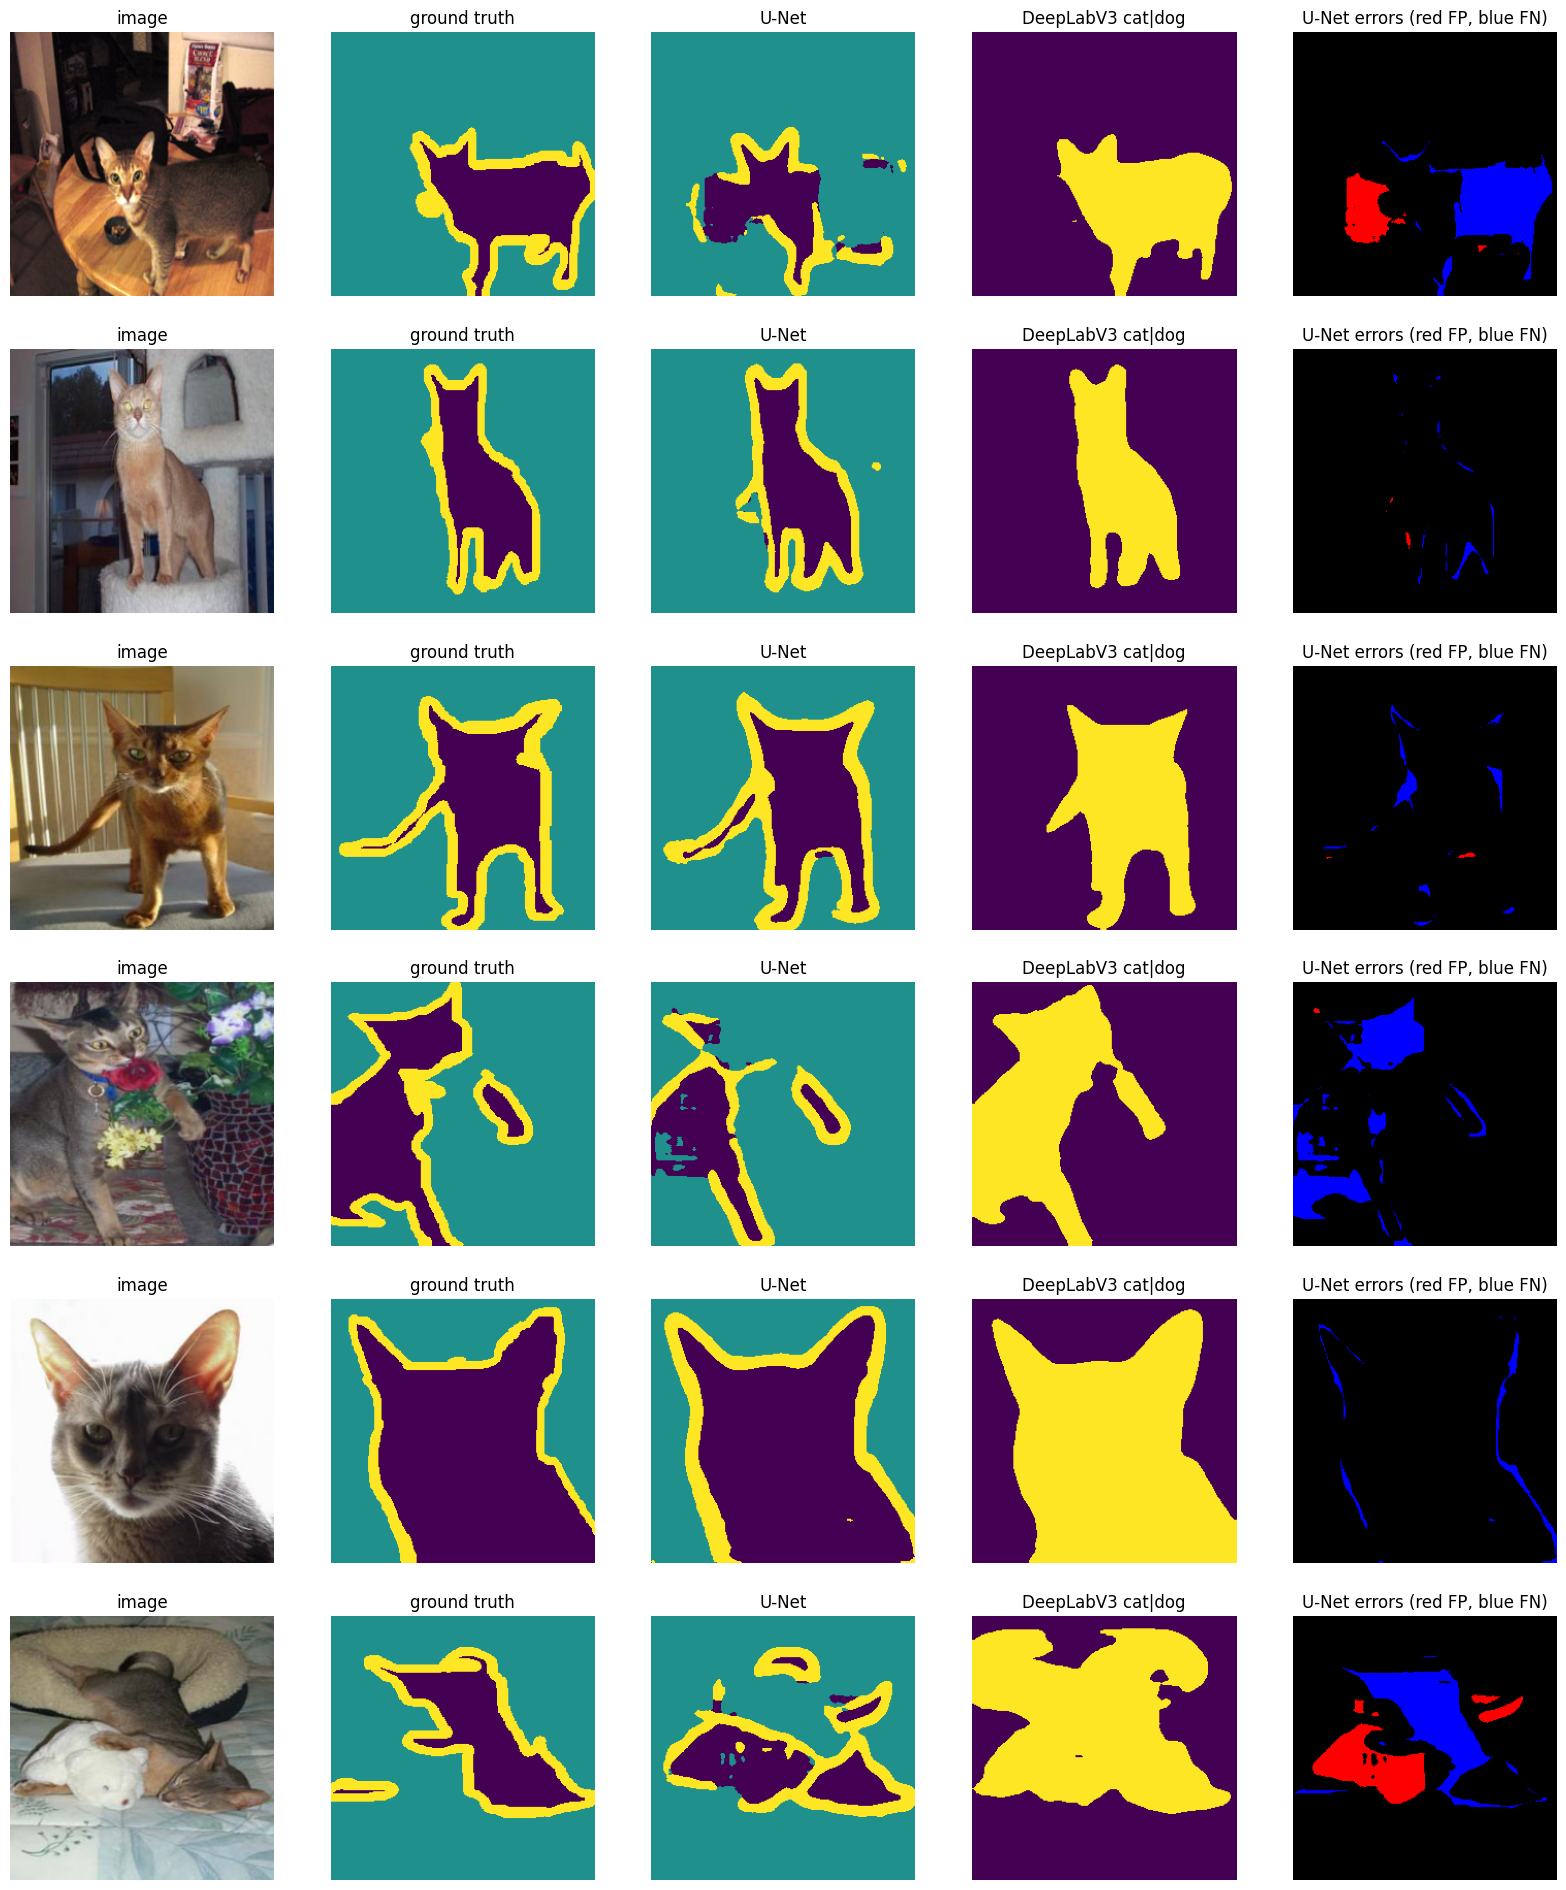

saved -> /content/week3_outputs/day3/day3_unet_vs_deeplab.png


In [14]:
@torch.no_grad()
def binary_pet_iou(n: int) -> tuple[dict, list]:
    unet.eval()
    stats = {"unet": [0, 0], "deeplab": [0, 0]}  # [intersection, union]
    examples = []
    for i in range(min(n, len(test_ids))):
        gt = test_y[i]
        valid = gt != 2
        gt_pet = gt == 0
        x = ((torch.from_numpy(test_x[i]).permute(2, 0, 1).float() / 255 - IMAGENET_MEAN) / IMAGENET_STD).unsqueeze(0).to(DEVICE)
        unet_pred = unet(x).argmax(1)[0].cpu().numpy()
        dl_pred = deeplab_logits(Image.fromarray(test_x[i]), out_size=(IMG_SIZE, IMG_SIZE)).argmax(0).cpu().numpy()
        for key, pet in [("unet", unet_pred == 0), ("deeplab", np.isin(dl_pred, PET_VOC_IDS))]:
            stats[key][0] += int((pet & gt_pet & valid).sum())
            stats[key][1] += int(((pet | gt_pet) & valid).sum())
        if i < 6:
            examples.append((test_x[i], gt, unet_pred, dl_pred))
    return {k: inter / max(union, 1) for k, (inter, union) in stats.items()}, examples


pet_iou, examples = binary_pet_iou(N_COMPARE)
print(f"Pet IoU on {min(N_COMPARE, len(test_ids))} test images (border ignored):")
print(f"  U-Net from scratch : {pet_iou['unet']:.4f}")
print(f"  DeepLabV3 zero-shot: {pet_iou['deeplab']:.4f}")

fig, axes = plt.subplots(len(examples), 5, figsize=(20, 4 * len(examples)))
for row, (image, gt, up, dp) in enumerate(examples):
    gt_pet = gt == 0
    err = np.zeros((*gt.shape, 3))
    err[(up == 0) & ~gt_pet & (gt != 2)] = [1, 0, 0]  # false positive = red
    err[(up != 0) & gt_pet] = [0, 0, 1]  # false negative = blue
    panels = [(image, "image"), (gt, "ground truth"), (up, "U-Net"), (np.isin(dp, PET_VOC_IDS), "DeepLabV3 cat|dog"), (err, "U-Net errors (red FP, blue FN)")]
    for col, (panel, title) in enumerate(panels):
        ax = axes[row, col]
        ax.imshow(panel, cmap="viridis" if panel.ndim == 2 else None)
        ax.set_title(title)
        ax.axis("off")
save_fig(fig, "day3_unet_vs_deeplab.png")

## Save results

In [15]:
summary = {
    "datasets": ["julinmaloof/the-oxfordiiit-pet-dataset (Kaggle)", "ultralytics/coco128 (Kaggle)"],
    "unet": {"img_size": IMG_SIZE, "epochs": EPOCHS, "base_channels": BASE_CHANNELS,
             "params_M": round(sum(p.numel() for p in unet.parameters()) / 1e6, 2),
             "best_val_mIoU": best_miou, "test": test_metrics},
    "pet_iou_border_ignored": pet_iou,
    "latency_ms_single_image": {"yolo26n-seg": round(yolo_seg_ms, 1), "maskrcnn_resnet50_fpn_v2": round(maskrcnn_ms, 1)},
    "full_run": FULL_RUN,
}
with open(OUTPUT_DIR / "day3_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "datasets": [
    "julinmaloof/the-oxfordiiit-pet-dataset (Kaggle)",
    "ultralytics/coco128 (Kaggle)"
  ],
  "unet": {
    "img_size": 256,
    "epochs": 25,
    "base_channels": 32,
    "params_M": 7.76,
    "best_val_mIoU": 0.7655988832367809,
    "test": {
      "pixel_acc": 0.9151569864476334,
      "mIoU": 0.7728422463885647,
      "IoU": {
        "pet": 0.8420789398649147,
        "background": 0.9146173857089192,
        "border": 0.5618304135918605
      },
      "Dice": {
        "pet": 0.9142701994374539,
        "background": 0.9554048683938664,
        "border": 0.7194512396512708
      }
    }
  },
  "pet_iou_border_ignored": {
    "unet": 0.8725016339624282,
    "deeplab": 0.9568693762377368
  },
  "latency_ms_single_image": {
    "yolo26n-seg": 88.6,
    "maskrcnn_resnet50_fpn_v2": 348.9
  },
  "full_run": true
}


## Takeaways (fill in with your numbers)

- Semantic output = `(C, H, W)` scores → one id per pixel; instance output = a variable-length list of (mask, box, class, score).
- U-Net test mIoU = ___; the `border` class is hardest because it is thin and ambiguous.
- Pet IoU: U-Net ___ vs zero-shot DeepLabV3 ___. A model pretrained on 10k+ labelled images can beat a small model trained from scratch on 3.3k images, which is the Week 2 transfer-learning lesson again.
- Next step if you want more: swap the U-Net encoder for a pretrained ResNet (e.g. `segmentation_models_pytorch`) and compare.

Next: Day 4 adds tracking on top of a detector.